# Transfer learning: spatial nested grid search

Run after `preprocessing_age_labels.ipynb` and `baseline.ipynb`. The Madrid source
forest is frozen. We search target-forest hyperparameters and blend weights using
only each permitted Amsterdam adaptation sample. Separate outer spatial folds
measure the complete selection procedure.

Applied the web-discovered [K-Dense scikit-learn skill](https://github.com/K-Dense-AI/scientific-agent-skills/blob/main/skills/scikit-learn/SKILL.md),
using the readable project copy in `docs/upstream-skills/`, and the verification skill.
No package dependency changes. These copies are not registered `.agents` installations.

**Evaluation boundary:** outer folds were viewed during earlier experiments.
These are development results, not untouched organizer-test scores. Never use
these outer scores to choose a different grid or a fixed winning configuration.


In [ ]:
from scripts.verify_grid_transfer import verify
from scripts.grid_transfer import run_experiment, FOREST_GRID, SOURCE_WEIGHTS
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

OUTPUT = ROOT / 'data/transfer_grid_search'
# Set True to rerun all 75 adaptation searches (several minutes).
# Existing results are verified below; missing results trigger a full run.
RUN_GRID_SEARCH = False
print('Forest grid:', FOREST_GRID)
print('Madrid blend weights:', SOURCE_WEIGHTS)

Forest grid: {'max_depth': [None, 12], 'max_features': ['sqrt', 0.5], 'min_samples_leaf': [2, 1]}
Madrid blend weights: [0.5, 0.25, 0.75, 0.0]


## Fit and select

The exhaustive `ParameterGrid` search evaluates 32 combinations over three
spatial inner folds (two only when necessary for class-complete training).
It reuses forest probabilities across blend weights to avoid redundant fits.
150 trees, `balanced_subsample`, and all 54 baseline predictors remain fixed.

Highest mean inner macro F1 determines the configuration separately for each
training sample. Exact ties use grid order, which places the baseline first.
Median imputation fits inside each training pipeline. Outer-fold locations and
blocks never enter adaptation or selection. Three seeded sampling repetitions
match the baseline exactly, at 5/25/50/100/200 labels per class.


In [ ]:
if RUN_GRID_SEARCH or not (OUTPUT / 'manifest.json').is_file():
    run_experiment()
verification = verify()

PASS: 7200 inner candidate/fold scores; 75 optimal selections; all spatial and label-budget exclusions; 150 held-out scores from 779,760 predictions; summary aggregation; five model reloads; hashes.


## Held-out development comparison

Mean scores first average sampling repetitions within each fold; ± is sample SD
across five spatial folds, not a confidence interval. A zero Madrid weight means
inner validation selected target-only prediction; it is not evidence of a transfer gain.


In [ ]:
summary = pd.read_csv(OUTPUT / 'summary.csv')
paired = pd.read_csv(OUTPUT / 'paired_fold_differences.csv')
selections = pd.read_csv(OUTPUT / 'selected_parameters.csv')
display(summary.round(4))
display(paired.groupby('samples_per_class').delta_macro_f1.agg(
    ['mean', 'min', 'max']).round(4))
for n, rows in selections.groupby('samples_per_class'):
    print(f'Labels/class={n}: inner-selected configurations (15 runs)')
    display(rows.groupby(['max_depth', 'max_features', 'min_samples_leaf', 'source_weight'], dropna=False)
            .size().sort_values(ascending=False).rename('selected_runs').reset_index())

,strategy,samples_per_class,macro_f1_mean,macro_f1_fold_sd,accuracy_mean,balanced_accuracy_mean
0,grid_selected,5,0.4543,0.0434,0.4806,0.4680
1,grid_selected,25,0.5424,0.0235,0.5555,0.5556
2,grid_selected,50,0.5858,0.0284,0.5964,0.5987
3,grid_selected,100,0.6174,0.0247,0.6257,0.6318
4,grid_selected,200,0.6355,0.0236,0.6432,0.6501
5,original_blend,5,0.4737,0.0279,0.4970,0.4841
6,original_blend,25,0.5494,0.0258,0.5652,0.5559
7,original_blend,50,0.5887,0.0254,0.6002,0.5928
8,original_blend,100,0.6168,0.0232,0.6256,0.6228
9,original_blend,200,0.6321,0.0233,0.6402,0.6374


,mean,min,max
samples_per_class,,,
5,-0.0194,-0.0563,-0.0011
25,-0.0070,-0.0107,-0.0042
50,-0.0029,-0.0267,0.0057
100,0.0007,-0.0029,0.0070
200,0.0034,-0.0032,0.0084


Labels/class=5: inner-selected configurations (15 runs)


,max_depth,max_features,min_samples_leaf,source_weight,selected_runs
0,NaN,sqrt,2,0.50,4
1,NaN,sqrt,1,0.50,2
2,NaN,0.5,1,0.00,1
3,NaN,0.5,1,0.50,1
4,NaN,0.5,1,0.25,1
5,NaN,0.5,1,0.75,1
6,NaN,0.5,2,0.25,1
7,NaN,0.5,2,0.75,1
8,NaN,0.5,2,0.50,1
9,NaN,sqrt,1,0.00,1


Labels/class=25: inner-selected configurations (15 runs)


,max_depth,max_features,min_samples_leaf,source_weight,selected_runs
0,NaN,0.5,1,0.25,4
1,NaN,0.5,2,0.50,3
2,NaN,sqrt,2,0.50,3
3,NaN,0.5,2,0.00,2
4,NaN,sqrt,2,0.25,2
5,NaN,sqrt,1,0.25,1


... (2 outputs left out)

Labels/class=100: inner-selected configurations (15 runs)


,max_depth,max_features,min_samples_leaf,source_weight,selected_runs
0,NaN,sqrt,2,0.25,3
1,NaN,0.5,2,0.25,2
2,12.0,0.5,1,0.25,1
3,12.0,0.5,2,0.00,1
4,12.0,sqrt,1,0.25,1
5,12.0,0.5,2,0.25,1
6,12.0,sqrt,2,0.25,1
7,12.0,sqrt,1,0.50,1
8,NaN,0.5,1,0.50,1
9,NaN,sqrt,1,0.00,1


Labels/class=200: inner-selected configurations (15 runs)


,max_depth,max_features,min_samples_leaf,source_weight,selected_runs
0,12.0,sqrt,2,0.25,4
1,12.0,sqrt,1,0.25,3
2,NaN,sqrt,1,0.25,3
3,NaN,0.5,2,0.25,3
4,12.0,0.5,2,0.00,1
5,NaN,sqrt,1,0.50,1


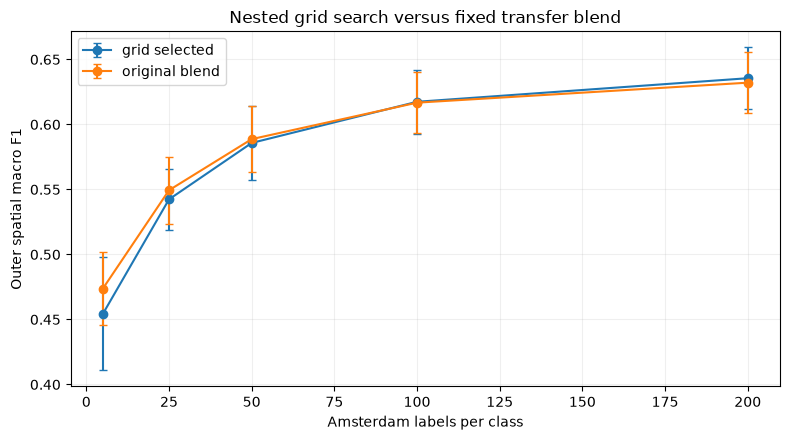

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for strategy, group in summary.groupby('strategy'):
    ax.errorbar(group.samples_per_class, group.macro_f1_mean,
                yerr=group.macro_f1_fold_sd, marker='o', capsize=3,
                label=strategy.replace('_', ' '))
ax.set(xlabel='Amsterdam labels per class', ylabel='Outer spatial macro F1',
       title='Nested grid search versus fixed transfer blend')
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
# Keep the exported plot outside the immutable experiment artifact manifest.
fig.savefig(ROOT / 'docs/transfer_grid_search.png', dpi=160)
plt.show()

## Class-level results and limitations

All per-class precision/recall/F1 scores are exported. Inspect both a low-label
budget (25/class) and the largest budget (200/class). Blocks can touch and remain
spatially correlated. City-specific class boundaries still need confirmation.
The configurations are optimal only within this finite grid and each training
sample; no universal optimum is established. Freeze the procedure before an
untouched organizer-test evaluation.


In [ ]:
class_summary = pd.read_csv(OUTPUT / 'class_summary.csv')
display(
    class_summary.loc[class_summary.samples_per_class.isin([25, 200])].round(4))
print((ROOT / 'docs/TRANSFER_GRID_SEARCH_RESULTS.md').read_text())

,strategy,samples_per_class,age_class,precision,recall,f1
4,grid_selected,25,1,0.6832,0.5949,0.6320
5,grid_selected,25,2,0.5469,0.5960,0.5627
6,grid_selected,25,3,0.5808,0.4451,0.4981
7,grid_selected,25,4,0.4140,0.5865,0.4768
16,grid_selected,200,1,0.7530,0.6594,0.7027
17,grid_selected,200,2,0.6120,0.6526,0.6307
18,grid_selected,200,3,0.6815,0.5882,0.6299
19,grid_selected,200,4,0.4948,0.7002,0.5789
24,original_blend,25,1,0.7228,0.5687,0.6337
25,original_blend,25,2,0.5169,0.6836,0.5872


# Spatial nested grid search for transfer learning

Frozen Madrid source forest plus an Amsterdam target forest. Exhaustive search evaluates 32 configurations: max_depth ∈ {None, 12}, max_features ∈ {sqrt, 0.5}, min_samples_leaf ∈ {2, 1}, Madrid source weight ∈ {0.5, 0.25, 0.75, 0}. 150 trees and balanced_subsample class weighting remain fixed.

Each configuration is selected by mean macro F1 over up to three spatial inner folds (two only if needed to retain all training classes). Imputation fits inside each inner training pipeline. The selected forest is refitted on the same limited adaptation sample. A zero source weight permits rejecting harmful transfer.

| Amsterdam labels/class | Original blend | Grid-selected | Paired Δ F1 | Improved folds |
| ---: | ---: | ---: | ---: | ---: |
| 5 | 0.4737 ± 0.0279 | 0.4543 ± 0.0434 | -0.0194 | 0/5 |
| 25 | 0.5494 ± 0.0258 | 0.5424 ± 0.0235 | -0.0070 | 0/5 |
| 50 | 0.5887 ± 0.0254 | 0.5858 ± 0.0284 | -0.0029 | 3/5 |
| 100 | 0.6168 ± 0.0232 | 0.

Skill reference: Kassis et al. (2026), _Scientific Agent Skills: A Library of
Procedural Knowledge for Research Agents_. https://doi.org/10.48550/arXiv.2609.00065.

Method reference: [scikit-learn nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
